# Application 4C — scaling, PCA, and groups in USArrests

**Question:** How do units and dimension reduction change a description of the same 50 states?

USArrests contains 1973 Murder, Assault, and Rape arrest rates per 100,000 residents, plus UrbanPop (% urban).
See [R's dataset notes](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/USArrests.html) for source/issues.
Use this historical table unchanged: it does not describe current ratings or individual risks.

**PCA directions** are unit feature-weight vectors; **scores** project centered states onto them.
**PVE/CPVE** are individual/cumulative shares of variance. **K-means** minimizes squared distances to group means (inertia).
**Silhouette** compares compactness and separation; **ARI** compares partitions independently of group IDs;
**RMSE** is root mean squared error.

Analyze all 50 rows descriptively, with no target class or held-out prediction claim.
Select K before interpreting states. Data are bundled locally.
See [lecture](04_clustering_and_pca.pdf) and [solution](Solutions/04_C_usarrests_solution.pdf).

## 1. Load data and inspect units

The loader finds bundled `data/USArrests.csv`. `read_csv(index_col=0)` keeps state names as identifiers,
not predictors. Select the four named columns and check shape, missingness, and unique names.
`std(ddof=1)` computes sample SD. PCA removes means but retains variance differences unless scaled.
Dataset notes are linked above; no download is required.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Find the bundled data from the notebook folder or a course ancestor.
locations = ("", "data", "FocusedContent/data", "StatisticalLearning/FocusedContent/data")
candidates = [base / folder / "USArrests.csv" for base in (Path.cwd(), *Path.cwd().parents)
              for folder in locations]
path = next((candidate for candidate in candidates if candidate.is_file()), None)
if path is None:
    raise FileNotFoundError("Missing USArrests.csv. Keep the FocusedContent/data folder with the notebooks; "
                            "in Colab, upload the CSV to /content/data or /content.")
data = pd.read_csv(path, index_col=0)
features = ["Murder", "Assault", "UrbanPop", "Rape"]
data = data[features]
assert data.shape == (50, 4) and data.index.is_unique
assert not data.isna().any().any()
X = data.to_numpy(dtype=float)
assert np.isfinite(X).all()
scale_table = pd.DataFrame({"mean": data.mean(), "sample SD": data.std(ddof=1),
                            "sample variance": data.var(ddof=1)})
display(scale_table)
print("Rows are state identifiers; first three:", list(data.index[:3]))

,mean,sample SD,sample variance
Murder,7.788,4.355510,18.970465
Assault,170.760,83.337661,6945.165714
UrbanPop,65.540,14.474763,209.518776
Rape,21.232,9.366385,87.729159


Rows are state identifiers; first three: ['Alabama', 'Alaska', 'Arizona']


## 2. Compare raw and standardized PCA

Fit PCA in original units, then on $Z_{ij}=(X_{ij}-\bar x_j)/s_j$ with sample SD (`ddof=1`).
Z's covariance is a correlation matrix with trace 4. `StandardScaler` uses divisor n instead:
these complete, nonconstant columns would have the same directions/PVE but different eigenvalues and score scales.

`PCA(svd_solver="full")` centers and learns four directions. `components_.T` lists features by component:
these are direction coefficients, not correlations or causal effects. For display, make each direction's
largest-magnitude coefficient positive and apply the same sign to its scores; the model is unchanged.

In [2]:
mean = X.mean(axis=0)
scale = X.std(axis=0, ddof=1)
assert np.all(scale > 0)
Z = (X-mean)/scale
raw_pca = PCA(svd_solver="full").fit(X)
standard_pca = PCA(svd_solver="full").fit(Z)
np.testing.assert_allclose(standard_pca.explained_variance_.sum(), 4, atol=1e-12)
pve_table = pd.DataFrame({"PC": np.arange(1, 5), "raw PVE": raw_pca.explained_variance_ratio_,
                          "standardized PVE": standard_pca.explained_variance_ratio_,
                          "standardized CPVE": np.cumsum(standard_pca.explained_variance_ratio_)})
display(pve_table)
directions = standard_pca.components_.T.copy()
signs = np.sign(directions[np.abs(directions).argmax(axis=0), np.arange(4)])
directions *= signs
scores = standard_pca.transform(Z) * signs
display(pd.DataFrame(directions, index=features, columns=["PC1", "PC2", "PC3", "PC4"]))
print("Raw first-PC direction:", raw_pca.components_[0])

,PC,raw PVE,standardized PVE,standardized CPVE
0,1,0.965534,0.620060,0.620060
1,2,0.027817,0.247441,0.867502
2,3,0.005800,0.089141,0.956642
3,4,0.000849,0.043358,1.000000


,PC1,PC2,PC3,PC4
Murder,0.535899,-0.418181,-0.341233,-0.649228
Assault,0.583184,-0.187986,-0.268148,0.743407
UrbanPop,0.278191,0.872806,-0.378016,-0.133878
Rape,0.543432,0.167319,0.817778,-0.089024


Raw first-PC direction: [0.04170432 0.99522128 0.04633575 0.0751555 ]


## 3. Interpret scores and reconstruct

Two-PC proximity need not reflect four-feature proximity. Reconstruct Z with the two original component rows,
then undo scaling. Never combine sign-adjusted scores with unadjusted directions.

Total standardized squared error is $(50-1)(\lambda_3+\lambda_4)$.
Report original-unit RMSE per feature: arrest-rate and percentage errors are not directly comparable.
This approximates the same 50 rows; it does not forecast.

,feature,two-PC reconstruction RMSE
0,Murder,1.459752
1,Assault,28.755166
2,UrbanPop,3.331670
3,Rape,4.540845


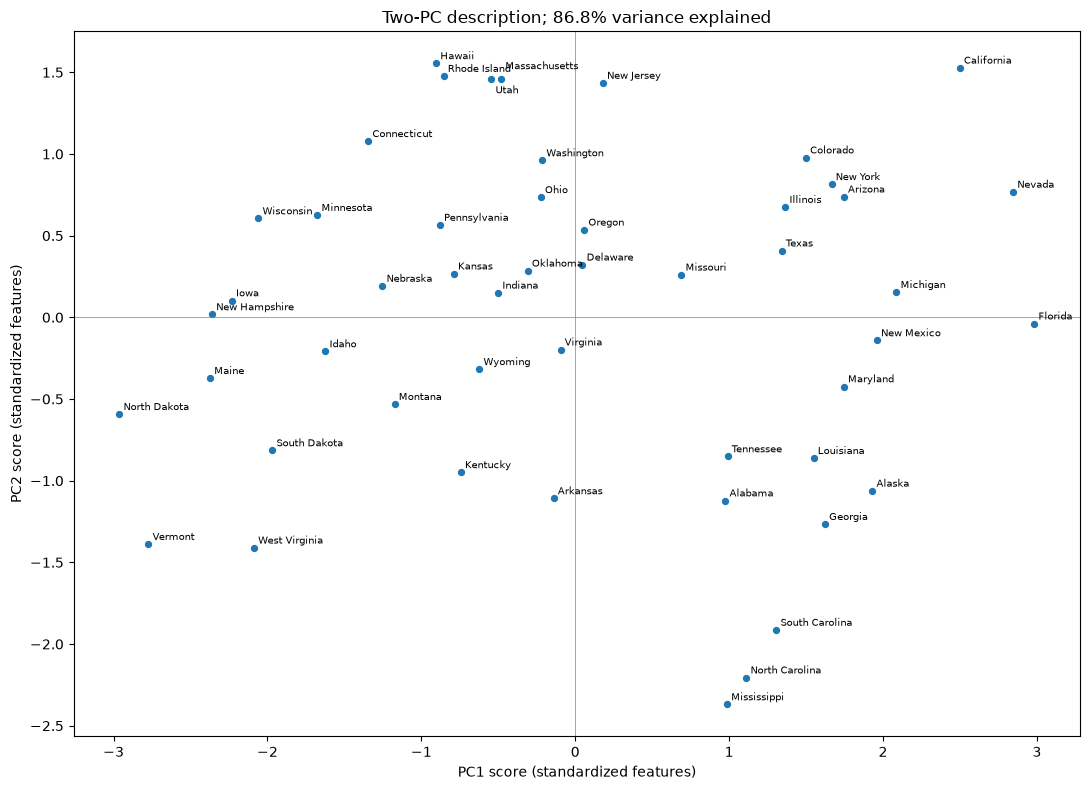

In [3]:
V2 = standard_pca.components_[:2]
Z_reconstruction = standard_pca.mean_ + (Z-standard_pca.mean_) @ V2.T @ V2
X_reconstruction = mean + Z_reconstruction*scale
np.testing.assert_allclose(np.sum((Z-Z_reconstruction)**2),
                           (len(Z)-1)*standard_pca.explained_variance_[2:].sum())
feature_rmse = np.sqrt(np.mean((X-X_reconstruction)**2, axis=0))
display(pd.DataFrame({"feature": features, "two-PC reconstruction RMSE": feature_rmse}))
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(scores[:, 0], scores[:, 1], s=18)
# Separate two nearby labels with fixed offsets for readability.
label_offsets = {"Utah": (3, -10), "Massachusetts": (3, 7)}
for name, xy in zip(data.index, scores[:, :2]):
    ax.annotate(name, xy, xytext=label_offsets.get(name, (3, 3)),
                textcoords="offset points", fontsize=7)
ax.axhline(0, color="gray", linewidth=.5); ax.axvline(0, color="gray", linewidth=.5)
ax.set(xlabel="PC1 score (standardized features)", ylabel="PC2 score (standardized features)",
       title=f"Two-PC description; {standard_pca.explained_variance_ratio_[:2].sum():.1%} variance explained")
plt.tight_layout(); plt.show()

## 4. Select groups in four-dimensional space

For K=2,...,6, fit `KMeans(n_init=50)` and maximize mean silhouette in full Z; ties favor smaller K.
Show group sizes and original-unit means. These describe scaled-space groups, not an unscaled K-means solution.
Group IDs and PC positions do not rank states as good/bad.

In [4]:
fits = {}
rows = []
for K in range(2, 7):
    fit = KMeans(n_clusters=K, n_init=50, random_state=23).fit(Z)
    fits[K] = fit
    rows.append({"K": K, "inertia": fit.inertia_, "silhouette": silhouette_score(Z, fit.labels_)})
selection = pd.DataFrame(rows)
selected_K = int(selection.loc[selection["silhouette"].idxmax(), "K"])
selected = fits[selected_K]
display(selection)
print("Selected K:", selected_K)
profiles = data.assign(cluster=selected.labels_).groupby("cluster")[features].mean()
profiles.insert(0, "size", np.bincount(selected.labels_, minlength=selected_K))
display(profiles)

,K,inertia,silhouette
0,2,102.862400,0.408489
1,3,78.483981,0.308136
2,4,56.403173,0.339689
3,5,48.944203,0.303078
4,6,42.963855,0.288293


Selected K: 2


,size,Murder,Assault,UrbanPop,Rape
cluster,,,,,
0,30,4.870,114.433333,63.633333,15.943333
1,20,12.165,255.250000,68.400000,29.165000


## 5. Compare methods and truncated coordinates

At the selected K, Ward minimizes added squared error and average linkage uses mean cross-group distance.
Fit both on full Z; separately fit K-means on two PC scores. Compare ARI with full-space K-means.
All silhouettes use full Z, including labels from the two-PC fit, to hold evaluation geometry fixed.

Full orthogonal PCA preserves Euclidean distance: check centered-row Gram matrices before/after four scores.
Truncation discards coordinate distances. Ward height is $\sqrt{2\Delta}$ in standardized Euclidean units.

,method,ARI vs full K-means,silhouette in full space
0,"K-means, 4 features",1.000000,0.408489
1,ward,0.919937,0.404794
2,average,1.000000,0.408489
3,"K-means, 2 PCs",1.000000,0.408489


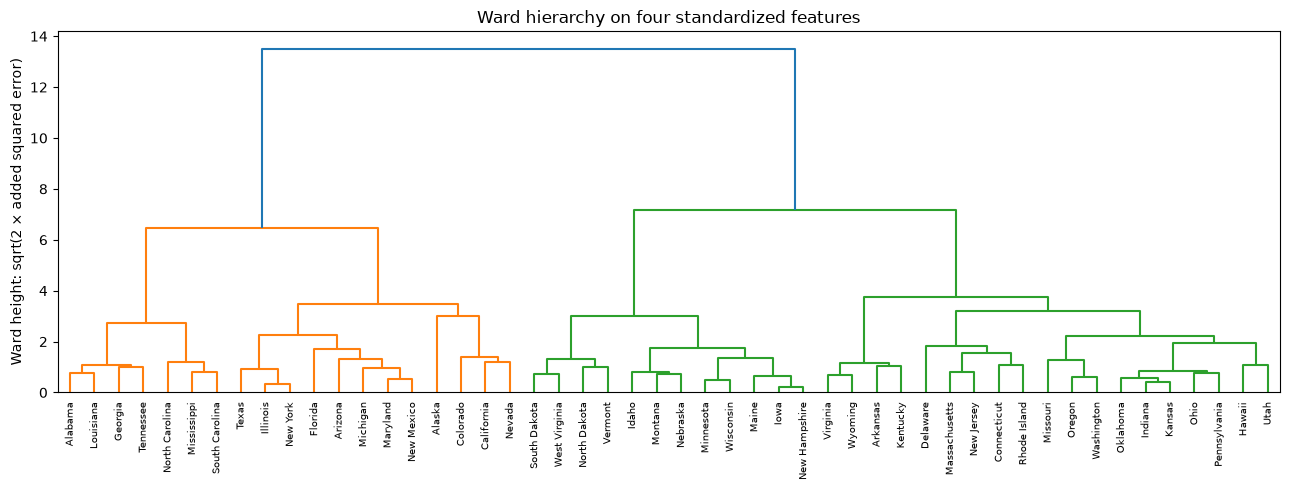

In [5]:
comparison = []
partitions = {"K-means, 4 features": selected.labels_}
for method in ["ward", "average"]:
    partitions[method] = AgglomerativeClustering(n_clusters=selected_K, linkage=method).fit_predict(Z)
partitions["K-means, 2 PCs"] = KMeans(n_clusters=selected_K, n_init=50, random_state=23).fit_predict(scores[:, :2])
for name, groups in partitions.items():
    comparison.append({"method": name, "ARI vs full K-means": adjusted_rand_score(selected.labels_, groups),
                       "silhouette in full space": silhouette_score(Z, groups)})
display(pd.DataFrame(comparison))
centered = Z-standard_pca.mean_
np.testing.assert_allclose(centered @ centered.T, scores @ scores.T, atol=1e-12)
merges = linkage(Z, method="ward", metric="euclidean")
fig, ax = plt.subplots(figsize=(13, 5))
dendrogram(merges, labels=list(data.index), leaf_rotation=90, leaf_font_size=7, ax=ax)
ax.set(title="Ward hierarchy on four standardized features", ylabel="Ward height: sqrt(2 × added squared error)")
plt.tight_layout(); plt.show()

## 6. Check subsample stability with refitted scaling

At fixed K, take ten independent 40-of-50 subsamples without replacement. Refit each mean/sample SD and K-means;
using the full-data scaler would answer a different question. Match state IDs before computing shared-row ARI.

The 45 pairwise scores are dependent diagnostics, not confidence-interval evidence.
States are not interchangeable independent draws: this measures sensitivity to removing historical rows, not future prediction.

In [6]:
rng = np.random.default_rng(23)
subsamples = []
for repeat in range(10):
    ids = np.sort(rng.choice(len(X), size=40, replace=False))
    subset = X[ids]
    subset_Z = (subset-subset.mean(axis=0))/subset.std(axis=0, ddof=1)
    groups = KMeans(n_clusters=selected_K, n_init=50, random_state=23).fit_predict(subset_Z)
    subsamples.append((ids, groups))
stability_rows = []
for a in range(len(subsamples)):
    for b in range(a+1, len(subsamples)):
        ids_a, labels_a = subsamples[a]
        ids_b, labels_b = subsamples[b]
        shared, pos_a, pos_b = np.intersect1d(ids_a, ids_b, return_indices=True)
        stability_rows.append({"shared states": len(shared), "ARI": adjusted_rand_score(labels_a[pos_a], labels_b[pos_b])})
stability = pd.DataFrame(stability_rows)
display(stability.describe().loc[["min", "25%", "50%", "75%", "max"]])

,shared states,ARI
min,30.0,1.0
25%,31.0,1.0
50%,32.0,1.0
75%,33.0,1.0
max,35.0,1.0


## Interpretation and documentation

Explain why the raw PC1 differs from standardized PC1; what PC2 contrasts; why two PCs can change groups despite explaining
most variation; and what the subsample ARIs do and do not establish. Group descriptions should remain tied to the four
measured historical variables. Arrest rates do not by themselves establish crime incidence or causes.

Consult the official [PCA API](https://scikit-learn.org/1.8/modules/generated/sklearn.decomposition.PCA.html),
[KMeans API](https://scikit-learn.org/1.8/modules/generated/sklearn.cluster.KMeans.html), and
[AgglomerativeClustering API](https://scikit-learn.org/1.8/modules/generated/sklearn.cluster.AgglomerativeClustering.html).
API methods differ: PCA transforms coordinates; K-means can assign new rows; agglomerative clustering has no standard new-row prediction method.